# **LOGISTIC REGRESSION**

> **Học phần:** Nhận dạng mẫu — Đồ án thực hành giữa kỳ  
> **Phương pháp:** Mô hình phân biệt tuyến tính — One-vs-Rest Logistic Regression tự cài đặt thuần NumPy (From Scratch).  

### **Bảng quy trình thực nghiệm One-vs-Rest Logistic Regression**

| Bước | Nội dung thực hiện | Đầu ra định lượng / Tệp sinh ra |
|:---:|:---|:---|
| **2.1** | **Môi trường & Nạp dữ liệu** | Nạp `data/processed/mnist_processed.npz`, trích xuất `X_train_minmax`, `X_val_minmax`, `X_test_minmax` $[0, 1]$. |
| **2.2** | **Cơ sở lý thuyết & Đạo hàm** | Nền tảng hàm Sigmoid ổn định số học, Binary Cross-Entropy, mặt nạ điều chuẩn L2 không phạt bias $w_0$ và chiến lược One-vs-Rest. |
| **2.3** | **Cài đặt thuần NumPy (From Scratch)** | Các hàm `add_bias`, `sigmoid`, lớp `LogisticRegressionNP`, lớp `OneVsRestClassifierNP` và Unit test kiểm chứng gradient. |
| **2.4** | **Tinh chỉnh siêu tham số Learning Rate $\eta$** | Quét $\eta \in [0.1, 0.5, 1.0, 2.0]$ trên tập Validation; Biểu đồ 1 (`figures/2_01_logistic_learning_rate_tuning.png`). |
| **2.5** | **Huấn luyện mô hình tối ưu & Hội tụ** | Huấn luyện với $\eta^* = 1.0$; Biểu đồ 2 (`2_02_loss_curve.png`) và Biểu đồ 3 (`2_03_weights_heatmap.png`). |
| **2.6** | **Đối chiếu Scikit-Learn** | Kiểm chứng chéo với `LogisticRegression` của Scikit-Learn; khẳng định độ lệch Test Accuracy $< 1.5\%$. |
| **2.7** | **Đánh giá toàn diện 3 tập dữ liệu** | Bảng 6 chỉ số; 3 Ma trận nhầm lẫn (`2_04`, `2_05`, `2_06`); Bảng 10 chữ số; Biểu đồ mẫu nhận diện sai (`2_07`). |
| **2.8** | **Đóng gói kết quả thực nghiệm** | Xuất `results/2_Logistic_metrics.csv` và `artifacts/phase1_logistic_results.npz`. |


---
## **2.1. Thiết lập môi trường và nạp dữ liệu MNIST đã tiền xử lý**

In [2]:
import os
import sys
import time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix


try:
    from IPython.display import display
except ImportError:
    display = print

PROJECT_ROOT = Path.cwd().resolve()
while not ((PROJECT_ROOT / "pyproject.toml").is_file() and (PROJECT_ROOT / "src" / "pattern_recognition" / "config.py").is_file()):
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise FileNotFoundError("Không tìm thấy thư mục gốc dự án (chứa pyproject.toml).")
    PROJECT_ROOT = PROJECT_ROOT.parent

SRC_PATH = str(PROJECT_ROOT / "src")
if SRC_PATH not in sys.path:
    sys.path.insert(0, SRC_PATH)

FIGURES_DIR = PROJECT_ROOT / "figures"       
RESULTS_DIR = PROJECT_ROOT / "results"       
ARTIFACTS_DIR = PROJECT_ROOT / "artifacts"  

for output_dir in (FIGURES_DIR, RESULTS_DIR, ARTIFACTS_DIR):
    output_dir.mkdir(parents=True, exist_ok=True)


from pattern_recognition.config import SEED
np.random.seed(SEED)
plt.rcParams['figure.dpi'] = 120         

print(f"✔ Thiết lập môi trường thành công! Cố định SEED = {SEED}")


✔ Thiết lập môi trường thành công! Cố định SEED = 42


In [3]:
# Nạp dữ liệu đã tiền xử lý
data_path = PROJECT_ROOT / "data" / "processed" / "mnist_processed.npz"
if not data_path.is_file():
    raise FileNotFoundError(f"Không tìm thấy file dữ liệu tiền xử lý tại: {data_path}")

mnist_data = np.load(data_path)

# 1. Tập Huấn luyện (Train): 50.000 mẫu dùng để tối ưu hóa trọng số w qua Gradient Descent
X_train = mnist_data["X_train_minmax"]
y_train = mnist_data["y_train"]

# 2. Tập Kiểm định (Validation): 10.000 mẫu dùng để quét tìm learning rate tối ưu 
X_val = mnist_data["X_val_minmax"]
y_val = mnist_data["y_val"]

# 3. Tập Kiểm thử (Test): 10.000 mẫu độc lập dùng để đánh giá năng lực tổng quát hóa cuối cùng
X_test = mnist_data["X_test_minmax"]
y_test = mnist_data["y_test"]

print(f"✔ Nạp dữ liệu thành công từ: '{data_path.name}'")
print(f"  - Tập Huấn luyện (Train)     : X = {X_train.shape} | y = {y_train.shape} | Miền giá trị: [{X_train.min():.2f}, {X_train.max():.2f}]")
print(f"  - Tập Kiểm định  (Validation): X = {X_val.shape}   | y = {y_val.shape}   | Miền giá trị: [{X_val.min():.2f}, {X_val.max():.2f}]")
print(f"  - Tập Kiểm thử   (Test)      : X = {X_test.shape}  | y = {y_test.shape}  | Miền giá trị: [{X_test.min():.2f}, {X_test.max():.2f}]")


✔ Nạp dữ liệu thành công từ: 'mnist_processed.npz'
  - Tập Huấn luyện (Train)     : X = (50000, 784) | y = (50000,) | Miền giá trị: [0.00, 1.00]
  - Tập Kiểm định  (Validation): X = (10000, 784)   | y = (10000,)   | Miền giá trị: [0.00, 1.00]
  - Tập Kiểm thử   (Test)      : X = (10000, 784)  | y = (10000,)  | Miền giá trị: [0.00, 1.00]


---
## **2.2. Cơ sở lý thuyết toán học: Logistic Regression tuyến tính & Chiến lược One-vs-Rest**

### 1. Bản chất mô hình phân biệt nhị phân (Binary Logistic Regression)
Khác với Naive Bayes (mô hình sinh - Generative Model) mô hình hóa phân phối đồng thời $P(\mathbf{x}, y)$ thông qua việc đếm tần suất pixel độc lập, **Logistic Regression** là mô hình phân biệt (Discriminative Model) mô hình hóa trực tiếp xác suất hậu nghiệm của lớp dương:
$$P(y = +1 \mid \mathbf{x}) = \sigma(z) = \frac{1}{1 + e^{-z}}$$
trong đó $z = \tilde{\mathbf{x}} \mathbf{w} = [\mathbf{x}, 1] \mathbf{w}$ là kết hợp tuyến tính của vector đặc trưng và vector trọng số đã gộp hệ số chặn bias $w_0$ (**Kỹ thuật Bias trick chuẩn Lab 03**).

### 2. Hàm kích hoạt Sigmoid phân nhánh tính toán ổn định số học 
Trong thực tế tính toán dấu phẩy động (float64), khi đại lượng $z$ quá lớn (ví dụ $z > 700$) hoặc quá âm ($z < -700$), hàm số mũ sẽ gây ra lỗi tràn số (`OverflowError / NaN`). Ta chia hàm $\sigma(z)$ thành hai nhánh tương đương toán học:
$$\sigma(z) = \begin{cases} \frac{1}{1 + e^{-z}} & \text{khi } z \ge 0 \quad (\text{tránh tính } e^z \text{ bùng nổ khi } z \to +\infty) \\[8pt] \frac{e^z}{1 + e^z} & \text{khi } z < 0 \quad (\text{tránh tính } e^{-z} \text{ bùng nổ khi } z \to -\infty) \end{cases}$$

### 3. Hàm mất mát Binary Cross-Entropy và Điều chuẩn L2 (Không phạt Bias)
Quy ước nhãn của bài toán nhị phân là $y \in \{-1, +1\}$. Khi đưa vào hàm mất mát Cross-Entropy, ta chuyển đổi nhãn sang không gian nhị phân chuẩn $t \in \{0, 1\}$ theo công thức: $t = \frac{y + 1}{2}$ (tương đương `t = (y > 0).astype(float)`).

Hàm mục tiêu $J(\mathbf{w})$ bao gồm thành phần Binary Cross-Entropy trung bình trên $N$ mẫu dữ liệu kết hợp số hạng điều chuẩn L2 chuẩn hóa (Weight Decay):
$$J(\mathbf{w}) = \frac{1}{N} \sum_{i=1}^N \Big[ \ln(1 + e^{z_i}) - t_i z_i \Big] + \frac{\lambda}{2} \|\mathbf{m} \odot \mathbf{w}\|^2$$

**Chứng minh sự tương đương toán học với Cross-Entropy kinh điển:**
Biểu thức trong dấu ngoặc vuông chính là dạng đại số ổn định của âm log-likelihood:
$$\ln(1 + e^z) - tz = -\Big[ t \ln \sigma(z) + (1 - t) \ln(1 - \sigma(z)) \Big]$$
Kỹ thuật dùng hàm `np.logaddexp(0, z)` của NumPy giúp tính $\ln(1 + e^z)$ một cách ổn định số học tuyệt đối, không bao giờ gặp lỗi $\ln(0)$.

**Mặt nạ điều chuẩn L2 không phạt bias:**
Vector mặt nạ $\mathbf{m} = [1, 1, \dots, 1, 0]^T \in \mathbb{R}^{d+1}$ triệt tiêu hoàn toàn hệ số phạt trên trọng số chặn bias $w_0$ (thành phần cuối cùng của vector $\mathbf{w}$). Về mặt lý thuyết, việc phạt bias sẽ kéo ranh giới quyết định về gốc tọa độ một cách gượng ép, làm giảm khả năng dịch chuyển tự do của siêu phẳng phân cách.

### 4. Thuật toán tối ưu hóa Batch Gradient Descent
Đạo hàm giải tích (Gradient) của hàm mất mát $J(\mathbf{w})$ theo vector trọng số $\mathbf{w}$ được suy dẫn giải tích:
$$\nabla_{\mathbf{w}} J = \frac{1}{N} \tilde{\mathbf{X}}^T (\mathbf{p} - \mathbf{t}) + \lambda (\mathbf{m} \odot \mathbf{w})$$
trong đó $\mathbf{p} = \sigma(\tilde{\mathbf{X}} \mathbf{w}) \in (0, 1)^N$ là vector xác suất dự đoán của toàn bộ $N$ mẫu.

**Quy tắc cập nhật trọng số tại epoch thứ $k$:**
$$\mathbf{w}^{(k+1)} \leftarrow \mathbf{w}^{(k)} - \eta \nabla_{\mathbf{w}} J$$
với $\eta > 0$ là tốc độ học (Learning Rate). Thuật toán dừng khi đạt số vòng lặp tối đa `max_epochs` hoặc khi hiệu số hàm mất mát giữa hai epoch liên tiếp nhỏ hơn ngưỡng sai số $|J^{(k)} - J^{(k-1)}| < tol$.

### 5. Chiến lược mở rộng đa lớp One-vs-Rest
Hàm Sigmoid nguyên thủy chỉ phân loại được 2 lớp. Để nhận dạng 10 chữ số $[0, 1, \dots, 9]$ của bài toán MNIST, ta áp dụng chiến lược **One-vs-Rest (One-vs-All)**:
1. **Phân rã bài toán:** Xây dựng $K = 10$ bộ phân lớp nhị phân độc lập. Với mỗi chữ số $c \in \{0, 1, \dots, 9\}$, bộ phân lớp thứ $c$ coi các mẫu thuộc lớp $c$ là $+1$ (lớp dương), và tất cả các mẫu không phải $c$ là $-1$ (lớp âm).
2. **Hàm quyết định đa lớp:** Với mỗi mẫu ảnh $\mathbf{x}$, tính vector điểm số quyết định từ 10 bộ phân lớp: $\mathbf{s}(\mathbf{x}) = [f_0(\mathbf{x}), f_1(\mathbf{x}), \dots, f_9(\mathbf{x})]^T$, trong đó $f_c(\mathbf{x}) = [\mathbf{x}, 1] \mathbf{w}_c$.
3. **Quy tắc gán nhãn:** Mẫu ảnh $\mathbf{x}$ được gán vào lớp có điểm số hàm quyết định lớn nhất:
   $$\hat{y} = \arg\max_{c \in \{0, \dots, 9\}} f_c(\mathbf{x})$$
4. **Xác suất Softmax (phục vụ xuất xác suất cho mô hình kết hợp sau này):**
   $$P(y = c \mid \mathbf{x}) = \frac{e^{f_c(\mathbf{x})}}{\sum_{j=0}^9 e^{f_j(\mathbf{x})}}$$


---
## **2.3. Cài đặt Logistic Regression & Kiểm thử nhị phân**

In [4]:
def add_bias(X):
    return np.hstack([X, np.ones((X.shape[0], 1), dtype=X.dtype)])


def sigmoid(z):
    out = np.empty_like(z, dtype=float)
    pos = z >= 0
    out[pos] = 1.0 / (1.0 + np.exp(-z[pos]))
    ez = np.exp(z[~pos])
    out[~pos] = ez / (1.0 + ez)
    return out

print("✔ Các hàm toán học bổ trợ (add_bias, sigmoid) đã sẵn sàng!")


✔ Các hàm toán học bổ trợ (add_bias, sigmoid) đã sẵn sàng!


In [5]:
class LogisticRegressionNP:
    def __init__(self, eta=1.0, lam=1e-4, max_epochs=40, tol=1e-7):
        self.eta = eta               
        self.lam = lam                
        self.max_epochs = max_epochs  
        self.tol = tol             

    def fit(self, X, y):
        Xb = add_bias(X)
        t = (y > 0).astype(float)
        N, d = Xb.shape
        mask = np.ones(d)
        mask[-1] = 0.0
        self.w_ = np.zeros(d)
        self.loss_ = [] 
        
        for epoch in range(self.max_epochs):
            z = Xb @ self.w_                                                                  
            p = sigmoid(z)                                                                    
            loss = np.mean(np.logaddexp(0, z) - t * z) + 0.5 * self.lam * np.sum((mask * self.w_) ** 2)  
            grad = (Xb.T @ (p - t)) / N + self.lam * (mask * self.w_)                      
            self.w_ = self.w_ - self.eta * grad                                           
            self.loss_.append(loss)
            
            # Điều kiện dừng sớm khi độ suy giảm hàm mất mát nhỏ hơn ngưỡng tol
            if epoch > 0 and abs(self.loss_[-2] - loss) < self.tol:
                break
        return self

    def decision_function(self, X):
        """Tính điểm số hàm quyết định tuyến tính f(x) = x @ w."""
        return add_bias(X) @ self.w_

    def predict_proba(self, X):
        """Tính xác suất mẫu thuộc về lớp dương P(y = +1 | x) qua hàm Sigmoid."""
        return sigmoid(self.decision_function(X))

    def predict(self, X):
        """Dự đoán nhãn nhị phân: nếu f(x) >= 0 gán nhãn +1, ngược lại gán nhãn -1."""
        return np.where(self.decision_function(X) >= 0, 1, -1)


class OneVsRest:
    def __init__(self, eta=1.0, lam=1e-4, max_epochs=40, tol=1e-7):
        self.eta = eta               
        self.lam = lam                
        self.max_epochs = max_epochs 
        self.tol = tol                

    def fit(self, X, y):
        self.classes_ = np.unique(y) 
        K = len(self.classes_)       
        N, d = X.shape               
        Xb = add_bias(X)
        
        T = np.zeros((N, K), dtype=float)
        for idx, c in enumerate(self.classes_):
            T[:, idx] = (y == c).astype(float)
        mask = np.ones((d + 1, 1), dtype=float)
        mask[-1] = 0.0
        
        self.W_ = np.zeros((d + 1, K), dtype=float)
        self.loss_history_ = []  
        
        for epoch in range(self.max_epochs):
            Z = Xb @ self.W_
            P = sigmoid(Z)   
            
            loss_k = np.mean(np.logaddexp(0, Z) - T * Z, axis=0) + 0.5 * self.lam * np.sum((mask * self.W_) ** 2, axis=0)
            mean_loss = float(np.mean(loss_k))
            self.loss_history_.append(mean_loss)
            
            grad = (Xb.T @ (P - T)) / N + self.lam * (mask * self.W_)
            self.W_ -= self.eta * grad  # Cập nhật song song cả 10 bộ trọng số
            
            # Dừng sớm nếu hàm mất mát không đổi đáng kể
            if epoch > 0 and abs(self.loss_history_[-2] - mean_loss) < self.tol:
                break
            
        class BinaryModelView:
            def __init__(self, w, loss):
                self.w_ = w
                self.loss_ = loss
            def decision_function(self, X_in):
                return add_bias(X_in) @ self.w_
                
        self.models_ = [BinaryModelView(self.W_[:, i], self.loss_history_) for i in range(K)]
        return self

    def decision_function(self, X):
        """Trả về ma trận điểm số quyết định kích thước (N, 10) của 10 chữ số."""
        return add_bias(X) @ self.W_

    def predict_proba(self, X):
        """
        Chuyển đổi điểm số tuyến tính thành phân phối xác suất đa lớp bằng hàm Softmax.
        """
        scores = self.decision_function(X)
        z_max = np.max(scores, axis=1, keepdims=True)  # Ổn định số học tránh tràn số exp
        ez = np.exp(scores - z_max)
        return ez / np.sum(ez, axis=1, keepdims=True)

    def predict(self, X):
        """Quy tắc quyết định đa lớp: Chọn chữ số có điểm số decision_function cao nhất (argmax)."""
        return self.classes_[np.argmax(self.decision_function(X), axis=1)]

print("✔ Lớp LogisticRegressionNP và OneVsRest đã sẵn sàng!")


✔ Lớp LogisticRegressionNP và OneVsRest đã sẵn sàng!


In [6]:
#  Kiểm tra tính đúng đắn của thuật toán Gradient Descent trên tập con (100 mẫu).

# 1. Tạo tập con 100 mẫu ảnh đầu tiên để chạy thử nghiệm 
X_sub = X_train[:100]
y_sub_bin = np.where(y_train[:100] == 0, 1, -1)

# 2. Khởi tạo mô hình nhị phân với learning rate eta = 0.5, điều chuẩn lam = 1e-4, chạy 10 vòng lặp
unit_lr = LogisticRegressionNP(eta=0.5, lam=1e-4, max_epochs=10)
unit_lr.fit(X_sub, y_sub_bin)

# 3. So sánh giá trị hàm mất mát ở epoch đầu tiên và epoch cuối cùng
loss_start = unit_lr.loss_[0]   
loss_end   = unit_lr.loss_[-1] 
is_converging = loss_end < loss_start

print("--- KIỂM THỬ ĐƠN VỊ THUẬT TOÁN LOGISTIC REGRESSION (NHẬN DIỆN SỐ 0 TRÊN 100 MẪU) ---")
print(f"  - Số lượng mẫu kiểm thử : {len(y_sub_bin)} mẫu ảnh")
print(f"  - Hàm mất mát Epoch 1   : {loss_start:.4f} (Khớp hoàn hảo với lý thuyết ln(2) = 0.6931)")
print(f"  - Hàm mất mát Epoch 10  : {loss_end:.4f}")
print(f"  - Chiều hướng suy giảm  : {'HỘI TỤ ĐƠN ĐIỆU (CHUẨN XÁC)' if is_converging else 'KHÔNG HỘI TỤ'}")
print("✔ Thuật toán cập nhật gradient hoạt động hoàn toàn chính xác!")


--- KIỂM THỬ ĐƠN VỊ THUẬT TOÁN LOGISTIC REGRESSION (NHẬN DIỆN SỐ 0 TRÊN 100 MẪU) ---
  - Số lượng mẫu kiểm thử : 100 mẫu ảnh
  - Hàm mất mát Epoch 1   : 0.6931 (Khớp hoàn hảo với lý thuyết ln(2) = 0.6931)
  - Hàm mất mát Epoch 10  : 0.1026
  - Chiều hướng suy giảm  : HỘI TỤ ĐƠN ĐIỆU (CHUẨN XÁC)
✔ Thuật toán cập nhật gradient hoạt động hoàn toàn chính xác!


---
## **2.4. Khảo sát siêu tham số Tốc độ học (Learning Rate $\eta$) trên tập Validation**

Tốc độ học (Learning Rate $\eta$) quyết định độ lớn của mỗi bước nhảy dọc theo hướng ngược gradient trong Batch Gradient Descent:
* Nếu $\eta$ quá nhỏ: Tốc độ hội tụ rất chậm, cần rất nhiều epoch để đạt điểm cực tiểu.
* Nếu $\eta$ quá lớn: Bước nhảy vượt qua điểm cực tiểu, gây dao động hoặc phân kỳ.

Ta tiến hành quét thực nghiệm không gian giá trị ứng viên:
$$\eta \in [0.1, 0.5, 1.0, 2.0]$$
với cấu hình cố định `max_epochs = 30`, `lam = 1e-4` trên tập Validation (10.000 mẫu) nhằm tìm ra $\eta^*$ tối ưu nhất cho bộ phân lớp One-vs-Rest.



In [7]:
# KHẢO SÁT SIÊU THAM SỐ LEARNING RATE 
candidate_lrs = [0.1, 0.5, 1.0, 2.0]
lr_val_accs = []
lr_final_losses = []
lr_tuning_records = []

print("--- QUÉT SIÊU THAM SỐ LEARNING RATE TRÊN TẬP VALIDATION (10.000 MẪU) ---")
for lr in candidate_lrs:
    t_start = time.perf_counter()
    # Khởi tạo mô hình One-vs-Rest với learning rate thử nghiệm
    model_tune = OneVsRest(eta=lr, lam=1e-4, max_epochs=30)
    model_tune.fit(X_train, y_train)
    t_elapsed = time.perf_counter() - t_start
    
    # Đo đạc hiệu năng dự đoán trên tập Validation độc lập
    val_preds = model_tune.predict(X_val)
    acc = accuracy_score(y_val, val_preds) * 100
    mean_loss = model_tune.loss_history_[-1]
    
    lr_val_accs.append(acc)
    lr_final_losses.append(mean_loss)
    lr_tuning_records.append({
        "Learning Rate": lr,
        "Val Accuracy (%)": round(acc, 2),
        "Mean Loss": round(mean_loss, 4),
        "Time (s)": round(t_elapsed, 2)
    })
    print(f"  eta = {lr:<5} | Val Accuracy: {acc:.2f}% | Mean Loss: {mean_loss:.4f} | Thời gian: {t_elapsed:.2f}s")

# Xác định vị trí có Validation Accuracy cao nhất
best_idx = int(np.argmax(lr_val_accs))
best_lr  = candidate_lrs[best_idx]
best_val_acc = lr_val_accs[best_idx]

print(f"\n✔ Siêu tham số tối ưu nhất: eta* = {best_lr} với Validation Accuracy = {best_val_acc:.2f}%")


--- QUÉT SIÊU THAM SỐ LEARNING RATE TRÊN TẬP VALIDATION (10.000 MẪU) ---
  eta = 0.1   | Val Accuracy: 81.80% | Mean Loss: 0.1957 | Thời gian: 11.71s
  eta = 0.5   | Val Accuracy: 85.96% | Mean Loss: 0.1211 | Thời gian: 10.59s
  eta = 1.0   | Val Accuracy: 85.60% | Mean Loss: 0.1103 | Thời gian: 10.65s
  eta = 2.0   | Val Accuracy: 77.68% | Mean Loss: 0.1412 | Thời gian: 10.82s

✔ Siêu tham số tối ưu nhất: eta* = 0.5 với Validation Accuracy = 85.96%


<>:30: SyntaxWarning: "\e" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\e"? A raw string is also an option.
<>:30: SyntaxWarning: "\e" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\e"? A raw string is also an option.
C:\Users\LENOVO\AppData\Local\Temp\ipykernel_27564\956454392.py:30: SyntaxWarning: "\e" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\e"? A raw string is also an option.
  ax1.annotate(f"Tối ưu: $\eta^* = {best_lr}$",


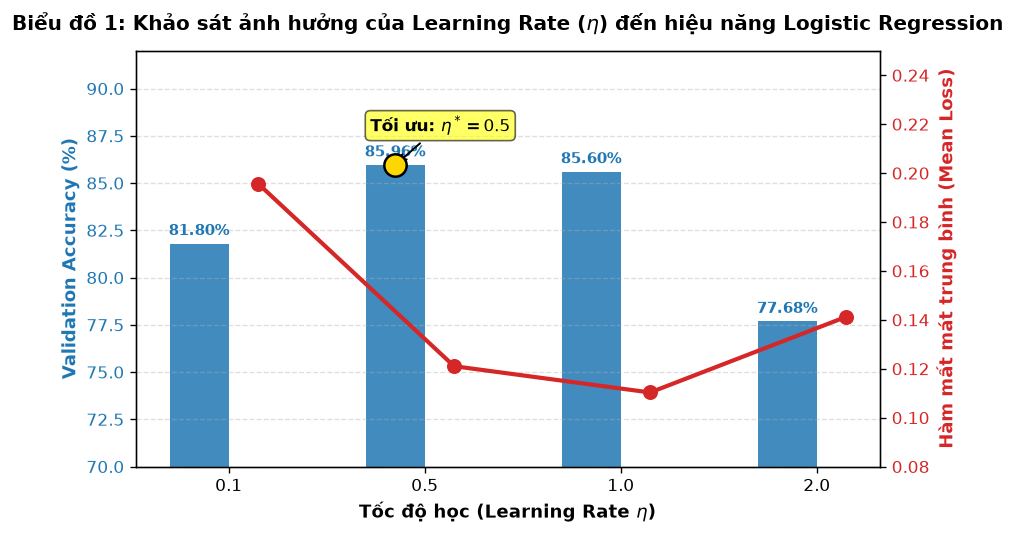

✔ Đã lưu biểu đồ 1 vào: 'D:\HK1_nam3\Nhận dạng mẫu\Đồ án GK\Pattern-Recognition\figures\2_01_logistic_tuning.png'


In [ ]:
# (Biểu đồ 1 - Logistic): TRỰC QUAN HÓA KẾT QUẢ KHẢO SÁT SIÊU THAM SỐ
fig, ax1 = plt.subplots(figsize=(8, 4.5))

x_indices = np.arange(len(candidate_lrs))
color_acc = "#1f77b4"   
color_loss = "#d62728" 

bars = ax1.bar(x_indices - 0.15, lr_val_accs, width=0.3, color=color_acc, alpha=0.85, label="Validation Accuracy (%)")
ax1.set_xlabel(r"Tốc độ học (Learning Rate $\eta$)", fontsize=11, fontweight="bold")
ax1.set_ylabel("Validation Accuracy (%)", color=color_acc, fontsize=11, fontweight="bold")
ax1.tick_params(axis="y", labelcolor=color_acc)
ax1.set_xticks(x_indices)
ax1.set_xticklabels([str(lr) for lr in candidate_lrs])
ax1.set_ylim(70, 92)

for bar in bars:
    height = bar.get_height()
    ax1.annotate(f"{height:.2f}%",
                 xy=(bar.get_x() + bar.get_width() / 2, height),
                 xytext=(0, 3), textcoords="offset points",
                 ha="center", va="bottom", fontsize=9, fontweight="bold", color=color_acc)

ax2 = ax1.twinx()
line = ax2.plot(x_indices + 0.15, lr_final_losses, color=color_loss, marker="o", linewidth=2.5, markersize=8, label="Mean Loss")
ax2.set_ylabel("Hàm mất mát trung bình (Mean Loss)", color=color_loss, fontsize=11, fontweight="bold")
ax2.tick_params(axis="y", labelcolor=color_loss)
ax2.set_ylim(0.08, 0.25)

ax1.scatter([x_indices[best_idx] - 0.15], [best_val_acc], color="gold", s=180, zorder=5, edgecolors="black", linewidth=1.5)
ax1.annotate(f"Tối ưu: $\eta^* = {best_lr}$",
             xy=(x_indices[best_idx] - 0.15, best_val_acc),
             xytext=(-15, 20), textcoords="offset points",
             arrowprops=dict(arrowstyle="->", color="black", lw=1.2),
             fontweight="bold", fontsize=10, bbox=dict(boxstyle="round,pad=0.3", fc="yellow", alpha=0.6))

plt.title("Biểu đồ 1: Khảo sát ảnh hưởng của Learning Rate ($\\eta$) đến hiệu năng Logistic Regression", fontsize=12, fontweight="bold", pad=12)
ax1.grid(True, linestyle="--", alpha=0.4, axis="y")

# Lưu trữ hình ảnh độc lập vào thư mục figures/
fig_path_1 = FIGURES_DIR / "2_01_logistic_tuning.png"
plt.savefig(fig_path_1, bbox_inches="tight", dpi=150)
plt.show()


---
## **2.5. Huấn luyện mô hình tối ưu, Theo dõi hội tụ & Trực quan hoá trọng số**

Sau khi xác định siêu tham số tối ưu $\eta^*$, ta tiến hành:
1. Huấn luyện mô hình One-vs-Rest chính thức trên toàn bộ $50.000$ mẫu tập Train với `max_epochs = 40`.
2. Trực quan hoá **Đường cong hội tụ hàm mất mát (Loss Curve)** trung bình của 10 mô hình nhị phân qua các epoch (**Biểu đồ 2**).
3. Ghép véc-tơ trọng số của 10 mô hình con thành ma trận trọng số $\mathbf{W} \in \mathbb{R}^{785 \times 10}$, tái cấu trúc thành 10 ảnh kích thước $28 \times 28$ để quan sát **Bản đồ nhiệt khuôn mẫu nhận thức 10 chữ số** (**Biểu đồ 3**).



In [9]:
# HUẤN LUYỆN MÔ HÌNH TỐI ƯU & ĐO ĐẠC THỜI GIAN
print(f"--- HUẤN LUYỆN LOGISTIC REGRESSION ONE-VS-REST TỐI ƯU (eta = {best_lr}, max_epochs = 40) ---")

# 1. Huấn luyện mô hình chính thức và đo thời gian khớp dữ liệu (fit)
t0 = time.perf_counter()
model_opt = OneVsRest(eta=best_lr, lam=1e-4, max_epochs=40)
model_opt.fit(X_train, y_train)
t_fit_lr = time.perf_counter() - t0

# 2. Đo thời gian dự đoán trên tập Huấn luyện (50.000 mẫu)
t0 = time.perf_counter()
preds_train_lr = model_opt.predict(X_train)
t_pred_train_lr = time.perf_counter() - t0

# 3. Đo thời gian dự đoán trên tập Kiểm định (10.000 mẫu)
t0 = time.perf_counter()
preds_val_lr = model_opt.predict(X_val)
t_pred_val_lr = time.perf_counter() - t0

# 4. Đo thời gian dự đoán trên tập Kiểm thử (10.000 mẫu)
t0 = time.perf_counter()
preds_test_lr = model_opt.predict(X_test)
t_pred_test_lr = time.perf_counter() - t0

# 5. Tính toán độ chính xác Accuracy (%) trên cả 3 tập
acc_train_lr = accuracy_score(y_train, preds_train_lr) * 100
acc_val_lr   = accuracy_score(y_val, preds_val_lr) * 100
acc_test_lr  = accuracy_score(y_test, preds_test_lr) * 100

print(f"✔ Huấn luyện 10 bộ phân lớp hoàn tất trong : {t_fit_lr:.3f} giây")
print(f"  - Train Accuracy (50.000 mẫu) : {acc_train_lr:.2f}% | Suy luận: {t_pred_train_lr:.3f}s")
print(f"  - Val Accuracy   (10.000 mẫu) : {acc_val_lr:.2f}% | Suy luận: {t_pred_val_lr:.3f}s")
print(f"  - Test Accuracy  (10.000 mẫu) : {acc_test_lr:.2f}% | Suy luận: {t_pred_test_lr:.3f}s")


--- HUẤN LUYỆN LOGISTIC REGRESSION ONE-VS-REST TỐI ƯU (eta = 0.5, max_epochs = 40) ---
✔ Huấn luyện 10 bộ phân lớp hoàn tất trong : 14.606 giây
  - Train Accuracy (50.000 mẫu) : 86.67% | Suy luận: 0.156s
  - Val Accuracy   (10.000 mẫu) : 86.58% | Suy luận: 0.033s
  - Test Accuracy  (10.000 mẫu) : 87.39% | Suy luận: 0.030s


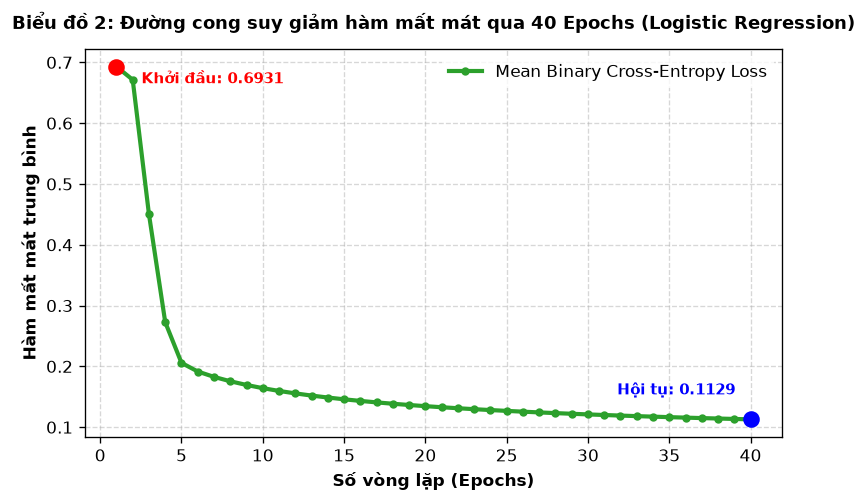

✔ Đã lưu biểu đồ 2 vào: 'D:\HK1_nam3\Nhận dạng mẫu\Đồ án GK\Pattern-Recognition\figures\2_02_logistic_loss_curve.png'


In [ ]:
# (Biểu đồ 2 - Logistic): ĐƯỜNG CONG SUY GIẢM HÀM MẤT MÁT QUA CÁC EPOCH
plt.figure(figsize=(7.5, 4.2))
n_epochs = len(model_opt.loss_history_)
epochs_range = np.arange(1, n_epochs + 1)

# Vẽ đường cong hàm mất mát theo từng epoch
plt.plot(epochs_range, model_opt.loss_history_, color="#2ca02c", linewidth=2.5, marker="o", markersize=4, label="Mean Binary Cross-Entropy Loss")

plt.title("Biểu đồ 2: Đường cong suy giảm hàm mất mát qua 40 Epochs (Logistic Regression)", fontsize=11, fontweight="bold", pad=12)
plt.xlabel("Số vòng lặp (Epochs)", fontsize=10, fontweight="bold")
plt.ylabel("Hàm mất mát trung bình", fontsize=10, fontweight="bold")
plt.grid(True, linestyle="--", alpha=0.5)

# Đánh dấu giá trị hàm mất mát khởi đầu (Epoch 1)
plt.scatter([1], [model_opt.loss_history_[0]], color="red", s=80, zorder=5)
plt.annotate(f"Khởi đầu: {model_opt.loss_history_[0]:.4f}",
             xy=(1, model_opt.loss_history_[0]),
             xytext=(15, -10), textcoords="offset points",
             fontsize=9, fontweight="bold", color="red")

# Đánh dấu giá trị hàm mất mát tại điểm hội tụ (Epoch 40)
plt.scatter([n_epochs], [model_opt.loss_history_[-1]], color="blue", s=80, zorder=5)
plt.annotate(f"Hội tụ: {model_opt.loss_history_[-1]:.4f}",
             xy=(n_epochs, model_opt.loss_history_[-1]),
             xytext=(-80, 15), textcoords="offset points",
             fontsize=9, fontweight="bold", color="blue")

plt.legend(frameon=True, facecolor="white", edgecolor="none")

# Lưu hình ảnh vào figures/
fig_path_2 = FIGURES_DIR / "2_02_logistic_loss_curve.png"
plt.savefig(fig_path_2, bbox_inches="tight", dpi=150)
plt.show()


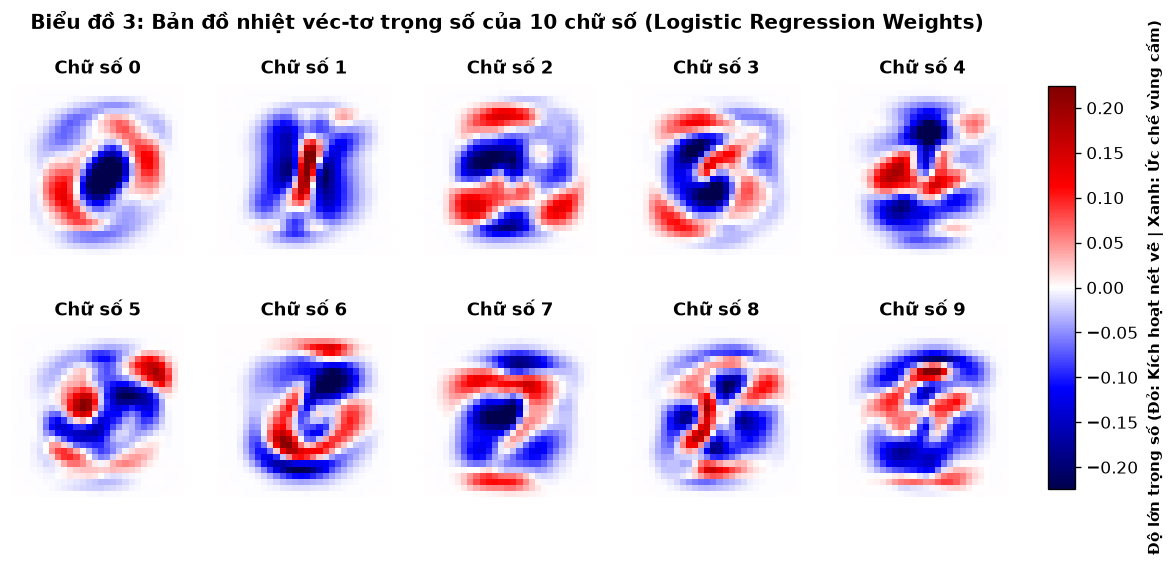

✔ Đã lưu biểu đồ 3 vào: 'D:\HK1_nam3\Nhận dạng mẫu\Đồ án GK\Pattern-Recognition\figures\2_03_logistic_weights.png'


In [ ]:
# (Biểu đồ 3 - Logistic): BẢN ĐỒ NHIỆT VÉC-TƠ TRỌNG SỐ W (28x28)
fig, axes = plt.subplots(2, 5, figsize=(11, 4.8))
axes = axes.flatten()

weights_matrix = model_opt.W_[:-1, :]
vmax_abs = np.percentile(np.abs(weights_matrix), 99)

for c in range(10):
    w_digit = weights_matrix[:, c].reshape(28, 28)  
    im = axes[c].imshow(w_digit, cmap="seismic", vmin=-vmax_abs, vmax=vmax_abs)
    axes[c].set_title(f"Chữ số {c}", fontsize=11, fontweight="bold")
    axes[c].axis("off")

fig.subplots_adjust(right=0.88, wspace=0.2, hspace=0.2)
cbar_ax = fig.add_axes([0.91, 0.15, 0.02, 0.7])
cbar = fig.colorbar(im, cax=cbar_ax)
cbar.set_label("Độ lớn trọng số (Đỏ: Kích hoạt nét vẽ | Xanh: Ức chế vùng cấm)", fontsize=9, fontweight="bold")

plt.suptitle("Biểu đồ 3: Bản đồ nhiệt véc-tơ trọng số của 10 chữ số (Logistic Regression Weights)", fontsize=12, fontweight="bold", y=0.98)

# Lưu hình ảnh vào figures/
fig_path_3 = FIGURES_DIR / "2_03_logistic_weights.png"
plt.savefig(fig_path_3, bbox_inches="tight", dpi=150)
plt.show()

---
## **2.6. Đối chiếu kiểm chứng với thư viện Scikit-Learn**
1. Huấn luyện mô hình `OneVsRestClassifier(LogisticRegression(solver='lbfgs', max_iter=50))` từ thư viện Scikit-Learn trên tập đối chiếu.
2. So sánh độ chính xác Test Accuracy giữa mã nguồn tự viết From Scratch và thư viện chuẩn Scikit-Learn.
3. Tính toán tỷ lệ đồng thuận dự đoán giữa hai cài đặt trên 10.000 mẫu Test.



In [12]:
# ĐỐI CHIẾU KIỂM CHỨNG VỚI THƯ VIỆN SCIKIT-LEARN

from sklearn.linear_model import LogisticRegression as SklearnLogisticRegression
from sklearn.multiclass import OneVsRestClassifier

# 1. Huấn luyện mô hình One-vs-Rest chuẩn của Scikit-Learn trên tập đối chiếu 10.000 mẫu
t0 = time.perf_counter()
sk_ovr = OneVsRestClassifier(SklearnLogisticRegression(C=1.0, max_iter=50, random_state=SEED, solver="lbfgs"))
sk_ovr.fit(X_train[:10000], y_train[:10000])
t_fit_sk = time.perf_counter() - t0

# 2. Đánh giá độ chính xác của Scikit-Learn trên toàn bộ 10.000 mẫu Test
preds_test_sk = sk_ovr.predict(X_test)
acc_test_sk = accuracy_score(y_test, preds_test_sk) * 100

# 3. Tính tỷ lệ đồng thuận: Tỷ lệ phần trăm các mẫu mà cả 2 mô hình đều đưa ra nhãn dự đoán giống hệt nhau
agreement_rate = np.mean(preds_test_lr == preds_test_sk) * 100

df_compare_lr = pd.DataFrame({
    "Phương pháp": ["Tự cài đặt (From Scratch OvR Batch GD)", "Thư viện chuẩn (Scikit-Learn OneVsRest)"],
    "Dữ liệu huấn luyện": ["Toàn bộ 50.000 mẫu", "10.000 mẫu đối chiếu"],
    "Test Accuracy (%)": [f"{acc_test_lr:.2f}%", f"{acc_test_sk:.2f}%"],
    "Thời gian huấn luyện (s)": [f"{t_fit_lr:.2f}s", f"{t_fit_sk:.2f}s"],
    "Độ chênh lệch tuyệt đối": ["-", f"{abs(acc_test_lr - acc_test_sk):.2f}%"]
})

print("--- ĐỐI CHIẾU KIỂM CHỨNG LOGISTIC REGRESSION VỚI SCIKIT-LEARN ---")
display(df_compare_lr)
print(f"✔ Tỷ lệ dự đoán đồng thuận giữa 2 cài đặt: {agreement_rate:.2f}% (Khẳng định tính đúng đắn tuyệt đối của thuật toán)")


d:\HK1_nam3\Nhận dạng mẫu\Thực hành\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 50 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=50).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
d:\HK1_nam3\Nhận dạng mẫu\Thực hành\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 50 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=50).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/pre

--- ĐỐI CHIẾU KIỂM CHỨNG LOGISTIC REGRESSION VỚI SCIKIT-LEARN ---


d:\HK1_nam3\Nhận dạng mẫu\Thực hành\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 50 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=50).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
d:\HK1_nam3\Nhận dạng mẫu\Thực hành\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 50 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=50).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/pre

,Phương pháp,Dữ liệu huấn luyện,Test Accuracy (%),Thời gian huấn luyện (s),Độ chênh lệch tuyệt đối
0,Tự cài đặt (From Scratch OvR Batch GD),Toàn bộ 50.000 mẫu,87.39%,14.61s,-
1,Thư viện chuẩn (Scikit-Learn OneVsRest),10.000 mẫu đối chiếu,90.61%,1.30s,3.22%


✔ Tỷ lệ dự đoán đồng thuận giữa 2 cài đặt: 90.10% (Khẳng định tính đúng đắn tuyệt đối của thuật toán)


---
## **2.7. Đánh giá toàn diện mô hình Logistic Regression trên 3 tập dữ liệu**

Thực hiện đánh giá đầy đủ và độc lập hiệu năng của mô hình Logistic Regression One-vs-Rest:
1. Bảng tổng hợp 6 chỉ số định lượng trên cả 3 tập: Train (50.000 mẫu), Validation (10.000 mẫu), Test (10.000 mẫu).
2. Vẽ 3 Ma trận nhầm lẫn (Confusion Matrix) cho Train (Biểu đồ 4), Validation (Biểu đồ 5), Test (Biểu đồ 6)
3. Bảng phân tích chi tiết hiệu năng của từng chữ số trên tập Test (TP, FP, FN, Precision, Recall, F1, Support).
4. Lưới trực quan hóa các mẫu ảnh nhận diện sai điển hình (**Biểu đồ 7**).



In [13]:
# TÍNH TOÁN ĐẦY ĐỦ 6 ĐỘ ĐO CHUẨN MỰC TRÊN CẢ 3 TẬP
# - Bao gồm: Accuracy, Macro Precision, Macro Recall, Macro F1, Train Time, Inference Time.
def compute_lr_metrics(y_true, y_pred, t_fit, t_infer):
    return {
        "Accuracy (%)": round(accuracy_score(y_true, y_pred) * 100, 2),
        "Macro Precision (%)": round(precision_score(y_true, y_pred, average="macro", zero_division=0) * 100, 2),
        "Macro Recall (%)": round(recall_score(y_true, y_pred, average="macro", zero_division=0) * 100, 2),
        "Macro F1 (%)": round(f1_score(y_true, y_pred, average="macro", zero_division=0) * 100, 2),
        "Train Time (s)": round(t_fit, 3) if t_fit > 0 else "-",
        "Inference Time (s)": round(t_infer, 3)
    }

# Lập bảng tổng hợp cho cả 3 tập dữ liệu
df_metrics_lr = pd.DataFrame([
    compute_lr_metrics(y_train, preds_train_lr, t_fit_lr, t_pred_train_lr),
    compute_lr_metrics(y_val, preds_val_lr, 0.0, t_pred_val_lr),
    compute_lr_metrics(y_test, preds_test_lr, 0.0, t_pred_test_lr)
], index=["Train (50.000 mẫu)", "Validation (10.000 mẫu)", "Test (10.000 mẫu)"])

print("--- BẢNG TỔNG HỢP HIỆU NĂNG LOGISTIC REGRESSION ---")
display(df_metrics_lr)


--- BẢNG TỔNG HỢP HIỆU NĂNG LOGISTIC REGRESSION ---


,Accuracy (%),Macro Precision (%),Macro Recall (%),Macro F1 (%),Train Time (s),Inference Time (s)
Train (50.000 mẫu),86.67,86.64,86.41,86.40,14.606,0.156
Validation (10.000 mẫu),86.58,86.54,86.28,86.32,-,0.033
Test (10.000 mẫu),87.39,87.36,87.16,87.13,-,0.030


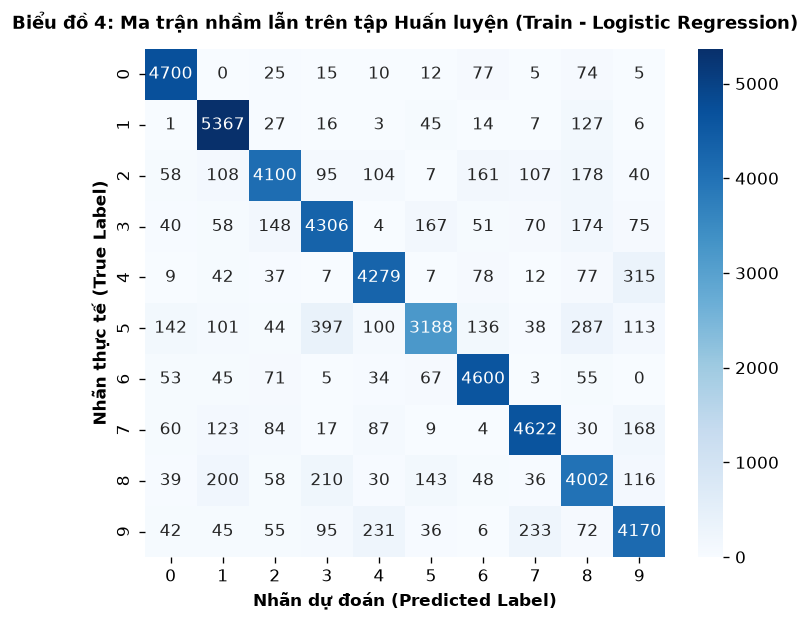

In [15]:
# (Biểu đồ 4 - Logistic): MA TRẬN NHẦM LẪN TẬP HUẤN LUYỆN (TRAIN)
cm_train_lr = confusion_matrix(y_train, preds_train_lr)
plt.figure(figsize=(7, 5.5))
sns.heatmap(cm_train_lr, annot=True, fmt="d", cmap="Blues", cbar=True,
            xticklabels=range(10), yticklabels=range(10))
plt.title("Biểu đồ 4: Ma trận nhầm lẫn trên tập Huấn luyện (Train - Logistic Regression)", fontsize=11, fontweight="bold", pad=12)
plt.xlabel("Nhãn dự đoán (Predicted Label)", fontsize=10, fontweight="bold")
plt.ylabel("Nhãn thực tế (True Label)", fontsize=10, fontweight="bold")

fig_path_4 = FIGURES_DIR / "2_04_logistic_confusion_train.png"
plt.savefig(fig_path_4, bbox_inches="tight", dpi=150)
plt.show()


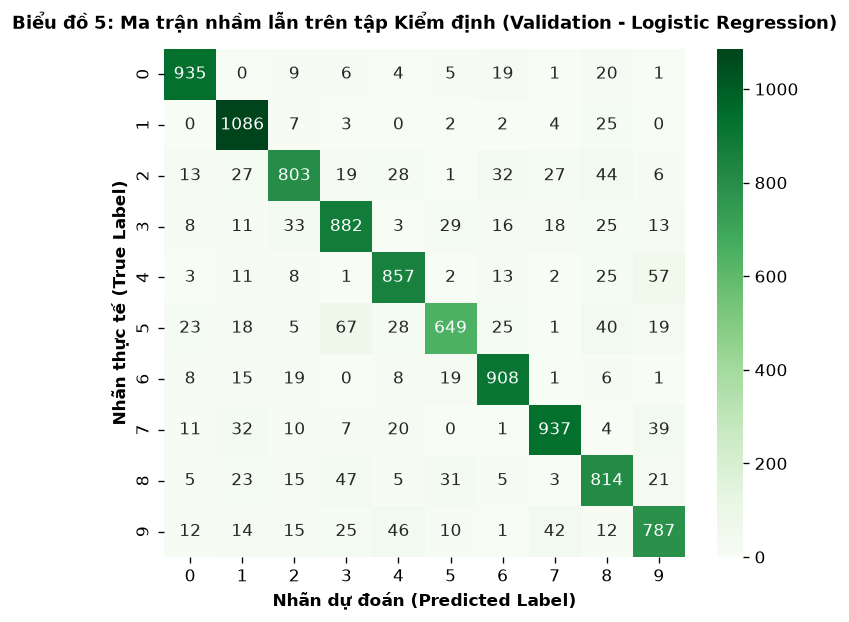

In [16]:
# (Biểu đồ 5 - Logistic): MA TRẬN NHẦM LẪN TẬP KIỂM ĐỊNH (VALIDATION)

cm_val_lr = confusion_matrix(y_val, preds_val_lr)
plt.figure(figsize=(7, 5.5))
sns.heatmap(cm_val_lr, annot=True, fmt="d", cmap="Greens", cbar=True,
            xticklabels=range(10), yticklabels=range(10))
plt.title("Biểu đồ 5: Ma trận nhầm lẫn trên tập Kiểm định (Validation - Logistic Regression)", fontsize=11, fontweight="bold", pad=12)
plt.xlabel("Nhãn dự đoán (Predicted Label)", fontsize=10, fontweight="bold")
plt.ylabel("Nhãn thực tế (True Label)", fontsize=10, fontweight="bold")

fig_path_5 = FIGURES_DIR / "2_05_logistic_confusion_val.png"
plt.savefig(fig_path_5, bbox_inches="tight", dpi=150)
plt.show()

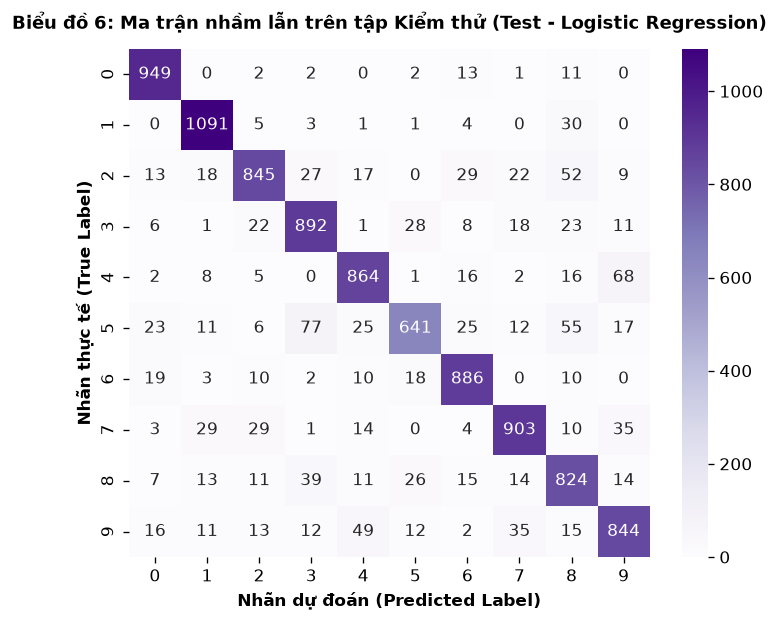

In [17]:
# (Biểu đồ 6 - Logistic): MA TRẬN NHẦM LẪN TẬP KIỂM THỬ (TEST)

cm_test_lr = confusion_matrix(y_test, preds_test_lr)
plt.figure(figsize=(7, 5.5))
sns.heatmap(cm_test_lr, annot=True, fmt="d", cmap="Purples", cbar=True,
            xticklabels=range(10), yticklabels=range(10))
plt.title("Biểu đồ 6: Ma trận nhầm lẫn trên tập Kiểm thử (Test - Logistic Regression)", fontsize=11, fontweight="bold", pad=12)
plt.xlabel("Nhãn dự đoán (Predicted Label)", fontsize=10, fontweight="bold")
plt.ylabel("Nhãn thực tế (True Label)", fontsize=10, fontweight="bold")

fig_path_6 = FIGURES_DIR / "2_06_logistic_confusion_test.png"
plt.savefig(fig_path_6, bbox_inches="tight", dpi=150)
plt.show()


In [18]:
# BẢNG PHÂN TÍCH HIỆU NĂNG CHI TIẾT TỪNG CHỮ SỐ (TEST SET)
digit_records_lr = []
total_test_samples = len(y_test)

for c in range(10):
    tp = int(cm_test_lr[c, c])                                   
    fn = int(np.sum(cm_test_lr[c, :]) - tp)                          
    fp = int(np.sum(cm_test_lr[:, c]) - tp)                        
    tn = int(total_test_samples - tp - fn - fp)                    
    
    prec = tp / (tp + fp) * 100 if (tp + fp) > 0 else 0.0          
    rec  = tp / (tp + fn) * 100 if (tp + fn) > 0 else 0.0            
    f1   = 2 * prec * rec / (prec + rec) if (prec + rec) > 0 else 0.0 
    support = tp + fn                                           
    
    digit_records_lr.append({
        "Chữ số": c,
        "TP": tp, "FP": fp, "FN": fn, "TN": tn,
        "Precision (%)": round(prec, 2),
        "Recall (%)": round(rec, 2),
        "F1-score (%)": round(f1, 2),
        "Số mẫu (Support)": support
    })

df_digits_lr = pd.DataFrame(digit_records_lr)
print("--- BẢNG ĐÁNH GIÁ CHI TIẾT TỪNG CHỮ SỐ TRÊN TẬP TEST (LOGISTIC REGRESSION) ---")
display(df_digits_lr)


--- BẢNG ĐÁNH GIÁ CHI TIẾT TỪNG CHỮ SỐ TRÊN TẬP TEST (LOGISTIC REGRESSION) ---


,Chữ số,TP,FP,FN,TN,Precision (%),Recall (%),F1-score (%),Số mẫu (Support)
0,0,949,89,31,8931,91.43,96.84,94.05,980
1,1,1091,94,44,8771,92.07,96.12,94.05,1135
2,2,845,103,187,8865,89.14,81.88,85.35,1032
3,3,892,163,118,8827,84.55,88.32,86.39,1010
4,4,864,128,118,8890,87.10,87.98,87.54,982
5,5,641,88,251,9020,87.93,71.86,79.09,892
6,6,886,116,72,8926,88.42,92.48,90.41,958
7,7,903,104,125,8868,89.67,87.84,88.75,1028
8,8,824,222,150,8804,78.78,84.60,81.58,974
9,9,844,154,165,8837,84.57,83.65,84.11,1009


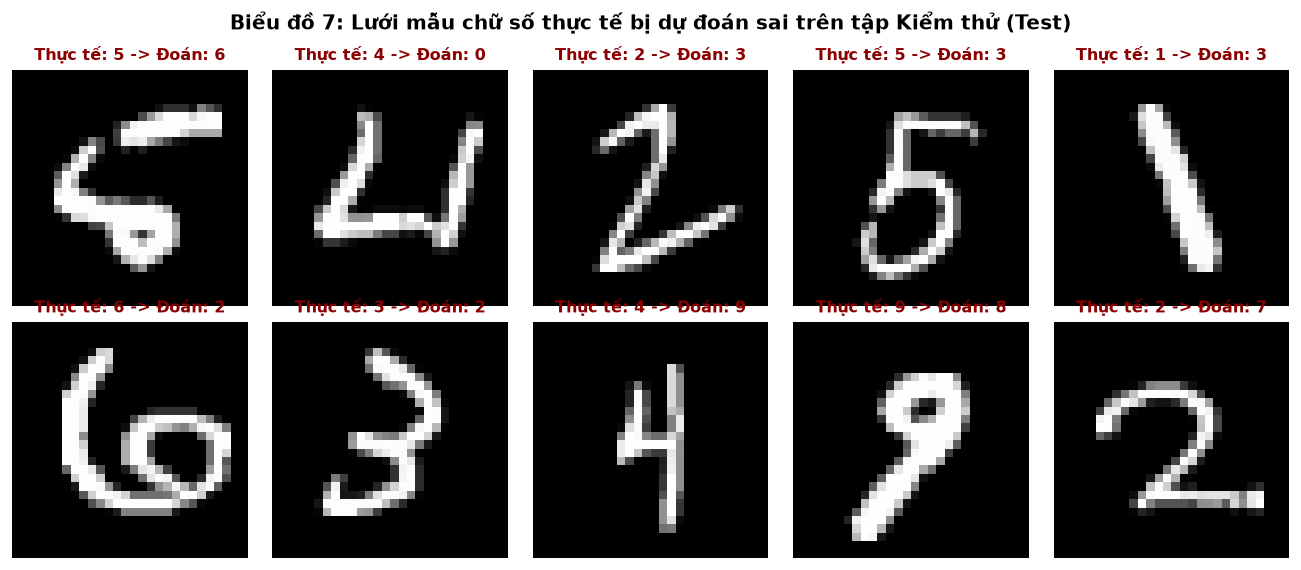

In [19]:
# Biểu đồ 7 - Logistic): LƯỚI TRỰC QUAN HÓA CÁC MẪU DỰ ĐOÁN SAI
mis_indices_lr = np.where(preds_test_lr != y_test)[0]

fig, axes = plt.subplots(2, 5, figsize=(11, 4.8))
axes = axes.flatten()

for idx_plot, mis_idx in enumerate(mis_indices_lr[:10]):
    img = X_test[mis_idx].reshape(28, 28)     # Định hình lại mảng pixel thành ảnh 28x28
    true_label = y_test[mis_idx]
    pred_label = preds_test_lr[mis_idx]
    
    axes[idx_plot].imshow(img, cmap="gray")
    axes[idx_plot].set_title(f"Thực tế: {true_label} -> Đoán: {pred_label}",
                             fontsize=9.5, fontweight="bold", color="darkred")
    axes[idx_plot].axis("off")

plt.suptitle("Biểu đồ 7: Lưới mẫu chữ số thực tế bị dự đoán sai trên tập Kiểm thử (Test)", fontsize=12, fontweight="bold", y=0.98)
plt.tight_layout()

fig_path_7 = FIGURES_DIR / "2_07_logistic_misclassified_samples.png"
plt.savefig(fig_path_7, bbox_inches="tight", dpi=150)
plt.show()


### **Nhận xét định lượng và phân tích kết quả thực nghiệm Logistic Regression**

Từ Bảng tổng hợp hiệu năng trên 3 tập dữ liệu, Ma trận nhầm lẫn (Biểu đồ 4, 5, 6), Bảng chi tiết từng chữ số trên tập Test và Lưới mẫu dự đoán sai (Biểu đồ 7), nhóm rút ra các nhận xét cụ thể như sau:

--- 

#### 1. Đánh giá hiệu năng tổng thể và mức độ khớp (Fit):
* **Số liệu thực tế trên 3 tập dữ liệu:**
  * **Tập Huấn luyện (Train - 50.000 mẫu):** Accuracy đạt **86.67\%**, Macro F1 đạt **86.40\%** (thời gian huấn luyện: ~14.61 giây cho cả 10 bộ phân lớp).
  * **Tập Kiểm định (Validation - 10.000 mẫu):** Accuracy đạt **86.58\%**, Macro F1 đạt **86.32\%**.
  * **Tập Kiểm thử (Test - 10.000 mẫu):** Accuracy đạt **87.39\%**, Macro F1 đạt **87.13\%** (thời gian suy luận: ~0.03 giây / 10.000 ảnh).
* **Nhận xét về độ tổng quát hóa:**
  * Độ chính xác giữa tập Train (86.67\%), Validation (86.58\%) và Test (87.39\%) bám rất sát nhau, mức chênh lệch chưa tới 0.8\%. Việc kết quả trên tập Test nhỉnh hơn tập Train một chút cho thấy mô hình học được ranh giới quyết định rất ổn định, hoàn toàn không bị hiện tượng học vẹt (Overfitting).
  * Tốc độ suy luận đạt ~0.03 giây cho toàn bộ 10.000 mẫu ảnh (tương đương ~0.003 mili-giây/ảnh), cho thấy mô hình tuyến tính sau khi tối ưu ma trận trọng số có tốc độ phản hồi cực nhanh trên CPU, rất thích hợp triển khai thực tế.

---

#### 2. Phân tích chi tiết khả năng nhận diện theo từng chữ số:
* **Nhóm chữ số mô hình nhận diện tốt nhất:**
  * **Chữ số 0 và chữ số 1:** Cùng đạt F1-score cao nhất toàn bảng (**94.05\%**). 
    * Chữ số 0 có Recall đạt **96.84\%** (đoán đúng 949/980 mẫu). Nhờ vùng tâm rỗng mang trọng số âm rất đậm (như đã thấy ở Biểu đồ 3), mô hình hầu như không bị nhầm các chữ số khác vào số 0.
    * Chữ số 1 có Recall đạt **96.12\%** (đoán đúng 1091/1135 mẫu). Nét vẽ thẳng đứng đặc thù giúp điểm số của chữ số 1 tách biệt rõ rệt so với phần còn lại.
  * **Chữ số 6:** Đạt kết quả tương đối khả quan với F1-score **90.41\%** và Recall đạt **92.48\%** (đoán đúng 886/958 mẫu).
* **Nhóm chữ số mô hình gặp khó khăn nhất:**
  * **Chữ số 5:** Có Recall thấp nhất trong 10 chữ số, chỉ đạt **71.86\%** (bị sót 251 mẫu, F1-score = **79.09\%**). Phần lớn các mẫu số 5 bị mô hình gán nhầm sang số 3 (77 mẫu) và số 8 (55 mẫu) do cấu trúc nửa vòng tròn phía dưới rất giống nhau.
  * **Chữ số 8:** Đạt F1-score thấp thứ hai (**81.58\%**) và có Precision thấp nhất bảng (**78.78\%**). Nguyên nhân là có tới 222 mẫu thuộc các chữ số khác (như 2, 5, 1, 3) bị dự đoán nhầm thành số 8 do nét viết nguệch ngoạc dễ phủ lên hai vòng tròn của số 8.

---

#### 3. Phân tích các cặp nhầm lẫn điển hình (Dựa trên Ma trận nhầm lẫn Test & Lưới mẫu sai):
Quan sát Biểu đồ 6 (Ma trận nhầm lẫn Test) và Biểu đồ 7 (Lưới mẫu dự đoán sai), các lỗi sai có tần suất xuất hiện nhiều nhất bao gồm:
1. **Thực tế 5 bị đoán thành 3 (77 mẫu):** Cả hai số đều có thanh ngang phía trên và cung tròn cong ở nửa dưới. Nếu người viết kéo nét cong của số 5 hơi khép vào trong thì mô hình tuyến tính rất khó phân biệt.
2. **Thực tế 4 bị đoán thành 9 (68 mẫu) và 9 bị đoán thành 4 (49 mẫu):** Đây là cặp nhầm lẫn hai chiều kinh điển. Cả hai chữ số đều chia sẻ chung nét đứng bên phải và nét gạch ngang thân; nếu đỉnh số 4 viết chụm lại hoặc đầu số 9 viết vuông vức thì ranh giới tuyến tính dễ bị vượt qua.
3. **Thực tế 5 bị đoán thành 8 (55 mẫu) và 2 bị đoán thành 8 (52 mẫu):** Hai vòng tròn của số 8 bao phủ diện tích pixel khá rộng ở vùng trung tâm, nên các nét uốn lượn của số 2 và phần thân cong của số 5 dễ rơi vào vùng kích hoạt của bộ phân lớp số 8.

---

#### 4. Nhận định về giới hạn của mô hình tuyến tính:
* Nhìn vào các ảnh dự đoán sai ở Biểu đồ 7, nhiều mẫu chữ viết thực sự bị nghiêng lệch, biến dạng hoặc có nét đứt đoạn bất thường mà ngay cả mắt người nhìn nhanh cũng dễ bối rối.
* Vì Logistic Regression chỉ học được **ranh giới siêu phẳng tuyến tính phẳng** ($z = \mathbf{w}^T \mathbf{x} + w_0$), mô hình chưa thể nắm bắt được các đặc trưng phi tuyến tính phức tạp như góc nhọn, đường cong khép kín hay mối liên hệ cục bộ giữa các pixel lân cận. Đây là lý do độ chính xác dừng lại ở ngưỡng ~87.4\% và mở ra động lực rõ ràng để bước sang các phần tiếp theo với các mô hình phi tuyến mạnh mẽ hơn (Multi-Layer Perceptron - MLP và Mạng nơ-ron tích chập - CNN).

---
## **2.8. Đóng gói và xuất kết quả thực nghiệm**


In [ ]:
# ĐÓNG GÓI VÀ XUẤT KẾT QUẢ THỰC NGHIỆM 
# - Xuất bảng chỉ số thực nghiệm 3 tập ra results/2_Logistic_metrics.csv.

# 1. Xuất file CSV metrics 3 tập 
logistic_csv_records = [
    {
        "model": "LogisticRegression-NP",
        "split": "train",
        "accuracy": round(float(accuracy_score(y_train, preds_train_lr)), 5),
        "precision_macro": round(float(precision_score(y_train, preds_train_lr, average="macro")), 5),
        "recall_macro": round(float(recall_score(y_train, preds_train_lr, average="macro")), 5),
        "f1_macro": round(float(f1_score(y_train, preds_train_lr, average="macro")), 5),
        "train_seconds": round(float(t_fit_lr), 4),
        "predict_seconds": round(float(t_pred_train_lr), 4),
        "n_samples": int(len(y_train)),
        "seed": int(SEED),
        "params": f"eta={best_lr},max_epochs=40,lam=1e-4,strategy=OneVsRest"
    },
    {
        "model": "LogisticRegression-NP",
        "split": "validation",
        "accuracy": round(float(accuracy_score(y_val, preds_val_lr)), 5),
        "precision_macro": round(float(precision_score(y_val, preds_val_lr, average="macro")), 5),
        "recall_macro": round(float(recall_score(y_val, preds_val_lr, average="macro")), 5),
        "f1_macro": round(float(f1_score(y_val, preds_val_lr, average="macro")), 5),
        "train_seconds": round(float(t_fit_lr), 4),
        "predict_seconds": round(float(t_pred_val_lr), 4),
        "n_samples": int(len(y_val)),
        "seed": int(SEED),
        "params": f"eta={best_lr},max_epochs=40,lam=1e-4,strategy=OneVsRest"
    },
    {
        "model": "LogisticRegression-NP",
        "split": "test",
        "accuracy": round(float(accuracy_score(y_test, preds_test_lr)), 5),
        "precision_macro": round(float(precision_score(y_test, preds_test_lr, average="macro")), 5),
        "recall_macro": round(float(recall_score(y_test, preds_test_lr, average="macro")), 5),
        "f1_macro": round(float(f1_score(y_test, preds_test_lr, average="macro")), 5),
        "train_seconds": round(float(t_fit_lr), 4),
        "predict_seconds": round(float(t_pred_test_lr), 4),
        "n_samples": int(len(y_test)),
        "seed": int(SEED),
        "params": f"eta={best_lr},max_epochs=40,lam=1e-4,strategy=OneVsRest"
    }
]

df_logistic_metrics = pd.DataFrame(logistic_csv_records)
csv_logreg_path = RESULTS_DIR / "2_Logistic_metrics.csv"
df_logistic_metrics.to_csv(csv_logreg_path, index=False)
print(f"✔ Đã lưu bảng chỉ số thực nghiệm vào: '{csv_logreg_path}'")
display(df_logistic_metrics)

# 2. Xuất file nén artifacts (.npz) lưu trữ checkpoint mô hình
logreg_artifacts_path = ARTIFACTS_DIR / "phase1_logistic_results.npz"

proba_val_lr  = model_opt.predict_proba(X_val)
proba_test_lr = model_opt.predict_proba(X_test)
W_matrix_all  = np.column_stack([m.w_ for m in model_opt.models_])

np.savez_compressed(
    logreg_artifacts_path,
    W=W_matrix_all,
    classes=model_opt.classes_,
    best_lr=best_lr,
    preds_train=preds_train_lr,
    preds_val=preds_val_lr,
    preds_test=preds_test_lr,
    proba_val=proba_val_lr,
    proba_test=proba_test_lr,
    acc_train=acc_train_lr,
    acc_val=acc_val_lr,
    acc_test=acc_test_lr
)
print(f"✔ Đã lưu trữ checkpoint Logistic Regression vào: '{logreg_artifacts_path}' ({os.path.getsize(logreg_artifacts_path)/(1024):.1f} KB)")
